# TP1 : Arbre de décision


Etape 1  — Importer les bibliothèques

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

Étape 2 — Créer le jeu de données

In [4]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 150

data = pd.DataFrame({
    "age": np.random.randint(18, 70, n),
    "revenu": np.random.randint(2500, 15000, n),
    "montant_credit": np.random.randint(5000, 100000, n),
    "historique": np.random.randint(0, 2, n)
})

data["credit"] = (
    (data["revenu"] >= 6000) &
    (data["montant_credit"] <= data["revenu"] * 8) &
    (data["historique"] == 1)
).astype(int)


In [5]:
print(data.head())
print("Nombre de clients :", len(data))

   age  revenu  montant_credit  historique  credit
0   56    6988           25932           1       1
1   69    2706           34855           1       0
2   46    7634           66434           1       0
3   32    8477           77694           0       0
4   60   10221           48016           0       0
Nombre de clients : 150


In [3]:
print(data.insert)

<bound method DataFrame.insert of      age  revenu  montant_credit  historique  credit
0     56    6988           25932           1       1
1     69    2706           34855           1       0
2     46    7634           66434           1       0
3     32    8477           77694           0       0
4     60   10221           48016           0       0
..   ...     ...             ...         ...     ...
145   22   11708           20338           0       0
146   43   14335           73027           1       1
147   31    4549           97772           0       0
148   56    7923           85135           1       0
149   44   14415           24508           1       1

[150 rows x 5 columns]>


Étape 3 — Séparer les variables explicatives X et la variable cible y

In [6]:
X = data[["age", "revenu", "montant_credit", "historique"]]
y = data["credit"]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (150, 4)
Dimensions de y : (150,)


Étape 4 — Diviser les données en entraînement et test

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Taille de X_train :", X_train.shape)
print("Taille de X_test :", X_test.shape)

Taille de X_train : (120, 4)
Taille de X_test : (30, 4)


Étape 5 — Entraîner l'arbre de décision

In [8]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

Étape 6 — Prédire la classe des clients de test


In [9]:
y_pred = model.predict(X_test)

print("Prédictions :", y_pred)

Prédictions : [0 1 1 1 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 1 1 1]


Étape 7 — Calculer les métriques d'évaluation

In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Accuracy :", accuracy)
print("Précision :", precision)
print("Rappel :", recall)
print("F1-score :", f1)

Accuracy : 0.9
Précision : 0.8
Rappel : 0.8888888888888888
F1-score : 0.8421052631578947


Étape 8 — Afficher la matrice de confusion

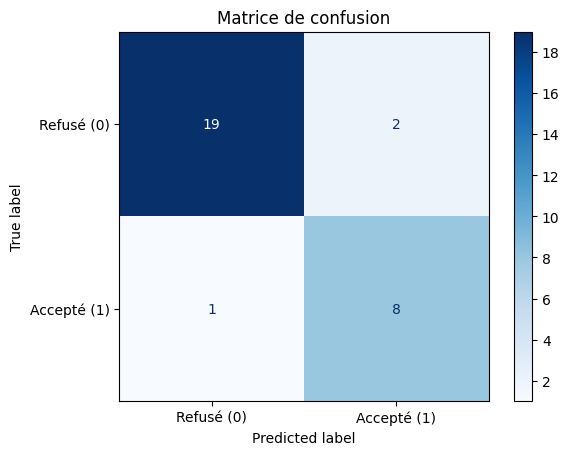

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Refusé (0)", "Accepté (1)"]
)

disp.plot(cmap="Blues")
plt.title("Matrice de confusion")
plt.show()

Étape 9 — Visualiser l'arbre de décision

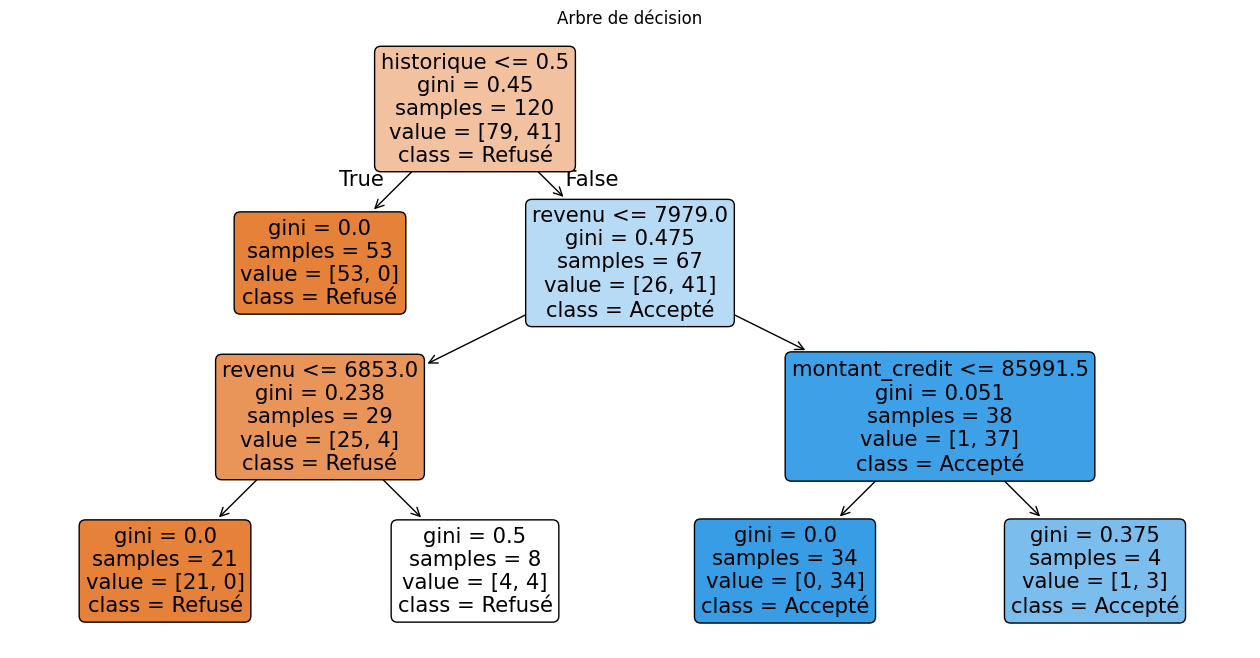

In [12]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Refusé", "Accepté"],
    filled=True,
    rounded=True
)

plt.title("Arbre de décision")
plt.show()

Étape 10 — Identifier la racine et la règle d'acceptation

In [13]:
root_index = model.tree_.feature[0]
root_variable = X.columns[root_index]

print("Variable à la racine :", root_variable)

Variable à la racine : historique


Étape 11 — Tester le modèle sur un nouveau client

In [14]:
nouveau_client = pd.DataFrame([{
    "age": 35,
    "revenu": 9000,
    "montant_credit": 30000,
    "historique": 1
}])

prediction = model.predict(nouveau_client)

print("Prédiction :", prediction[0])

Prédiction : 1


Étape 12 — Modifier les paramètres du modèle
*

In [15]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

for profondeur in [2, 3, 5]:
    modele_test = DecisionTreeClassifier(
        criterion="gini",
        max_depth=profondeur,
        random_state=42
    )

    modele_test.fit(X_train, y_train)
    predictions = modele_test.predict(X_test)

    print("Profondeur :", profondeur)
    print("Accuracy :", accuracy_score(y_test, predictions))
    print("F1-score :", f1_score(y_test, predictions, zero_division=0))
    print("--------------------")

Profondeur : 2
Accuracy : 0.9
F1-score : 0.8421052631578947
--------------------
Profondeur : 3
Accuracy : 0.9
F1-score : 0.8421052631578947
--------------------
Profondeur : 5
Accuracy : 0.9
F1-score : 0.8421052631578947
--------------------


Étape 13 — Utiliser la validation croisée (Cross-validation)

In [16]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for profondeur in [2, 3, 5]:
    modele_test = DecisionTreeClassifier(
        criterion="gini",
        max_depth=profondeur,
        random_state=42
    )

    scores = cross_val_score(
        modele_test,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    print("Profondeur :", profondeur)
    print("Scores :", scores)
    print("Accuracy moyenne :", scores.mean())
    print("--------------------")

Profondeur : 2
Scores : [0.86666667 0.9        0.93333333 0.93333333 0.96666667]
Accuracy moyenne : 0.9200000000000002
--------------------
Profondeur : 3
Scores : [0.86666667 0.86666667 0.93333333 0.93333333 0.96666667]
Accuracy moyenne : 0.9133333333333334
--------------------
Profondeur : 5
Scores : [0.93333333 0.86666667 0.96666667 0.96666667 0.96666667]
Accuracy moyenne : 0.9400000000000001
--------------------


Étape 14 — Choisir le meilleur modèle et justifier le choix

In [17]:
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

resultats = []

for profondeur in [2, 3, 5]:
    modele_test = DecisionTreeClassifier(
        criterion="gini",
        max_depth=profondeur,
        random_state=42
    )

    scores = cross_val_score(
        modele_test,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    resultats.append((profondeur, scores.mean()))

meilleure_profondeur = max(resultats, key=lambda x: x[1])[0]

meilleur_modele = DecisionTreeClassifier(
    criterion="gini",
    max_depth=meilleure_profondeur,
    random_state=42
)

meilleur_modele.fit(X_train, y_train)
predictions = meilleur_modele.predict(X_test)

print("Meilleure profondeur :", meilleure_profondeur)
print("Accuracy sur le test :", accuracy_score(y_test, predictions))
print("F1-score sur le test :", f1_score(
    y_test, predictions, zero_division=0
))

Meilleure profondeur : 5
Accuracy sur le test : 0.9
F1-score sur le test : 0.8421052631578947
